In [2]:
# import the dataset
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer


import warnings
warnings.filterwarnings('ignore')



In [3]:
bike = pd.read_csv('data_bike_sharing.csv')
bike

,dteday,hum,weathersit,holiday,season,atemp,temp,hr,casual,registered,cnt
0,2011-12-09,0.62,1,0,4,0.3485,0.36,16,24,226,250
1,2012-06-17,0.64,1,0,2,0.5152,0.54,4,2,16,18
2,2011-06-15,0.53,1,0,2,0.6212,0.62,23,17,90,107
3,2012-03-31,0.87,2,0,2,0.3485,0.36,8,19,126,145
4,2012-07-31,0.55,1,0,3,0.6970,0.76,18,99,758,857
...,...,...,...,...,...,...,...,...,...,...,...
12160,2012-01-25,0.75,1,0,1,0.2273,0.24,7,14,243,257
12161,2012-07-06,0.62,1,0,3,0.7424,0.78,0,39,63,102
12162,2012-02-20,0.60,2,1,1,0.2121,0.24,5,0,6,6
12163,2012-03-31,0.77,2,0,2,0.4242,0.42,2,14,55,69


## Data Quality Check

In [4]:
bike.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      12165 non-null  object 
 1   hum         12165 non-null  float64
 2   weathersit  12165 non-null  int64  
 3   holiday     12165 non-null  int64  
 4   season      12165 non-null  int64  
 5   atemp       12165 non-null  float64
 6   temp        12165 non-null  float64
 7   hr          12165 non-null  int64  
 8   casual      12165 non-null  int64  
 9   registered  12165 non-null  int64  
 10  cnt         12165 non-null  int64  
dtypes: float64(3), int64(7), object(1)
memory usage: 1.0+ MB


There is data type error for dteday column; it should be DateTime

There are data types error for weathersit, holiday, season, hr columns; it should be Category

In [5]:
# percentage of missing values
missing_columns = (bike.isnull().sum())*100/len(bike)
missing_rows = (bike.isnull().sum(axis=1))*100/len(bike)
display(missing_columns,missing_rows)

dteday        0.0
hum           0.0
weathersit    0.0
holiday       0.0
season        0.0
atemp         0.0
temp          0.0
hr            0.0
casual        0.0
registered    0.0
cnt           0.0
dtype: float64

0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
12160    0.0
12161    0.0
12162    0.0
12163    0.0
12164    0.0
Length: 12165, dtype: float64

There are no missing values either in columns or rows.

In [6]:
# check duplicate
bike.duplicated().sum()

0

There are no duplicate values.

## Removing redundant & unwanted columns

In [7]:
bike['dteday'] = pd.to_datetime(bike['dteday'])
bike['day'] = bike['dteday'].dt.day_of_week
bike['month'] = bike['dteday'].dt.month

In [8]:
bike.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      12165 non-null  datetime64[ns]
 1   hum         12165 non-null  float64       
 2   weathersit  12165 non-null  int64         
 3   holiday     12165 non-null  int64         
 4   season      12165 non-null  int64         
 5   atemp       12165 non-null  float64       
 6   temp        12165 non-null  float64       
 7   hr          12165 non-null  int64         
 8   casual      12165 non-null  int64         
 9   registered  12165 non-null  int64         
 10  cnt         12165 non-null  int64         
 11  day         12165 non-null  int32         
 12  month       12165 non-null  int32         
dtypes: datetime64[ns](1), float64(3), int32(2), int64(7)
memory usage: 1.1 MB


In [9]:
bike_new=bike[['hum','weathersit','holiday','season','temp','atemp','hr','casual','day','month']]
bike_new.columns

Index(['hum', 'weathersit', 'holiday', 'season', 'temp', 'atemp', 'hr',
       'casual', 'day', 'month'],
      dtype='object')

In [10]:
# Define the time ranges
bins = [-1, 5, 11, 17, 23]
labels = ['Night', 'Morning', 'Day', 'Evening']

# Replace the 'hr' column with the new time ranges
bike_new['hr'] = pd.cut(bike_new['hr'], bins=bins, labels=labels)

## Outlier Handling

In [11]:
num_columns = bike_new[['hum','temp','atemp','casual']]


In [12]:
num_columns.describe().loc[['max','50%','min','mean']]

,hum,temp,atemp,casual
max,1.000000,1.000000,1.000000,362.000000
50%,0.620000,0.500000,0.484800,17.000000
min,0.000000,0.020000,0.000000,0.000000
mean,0.625451,0.498185,0.476996,35.834443


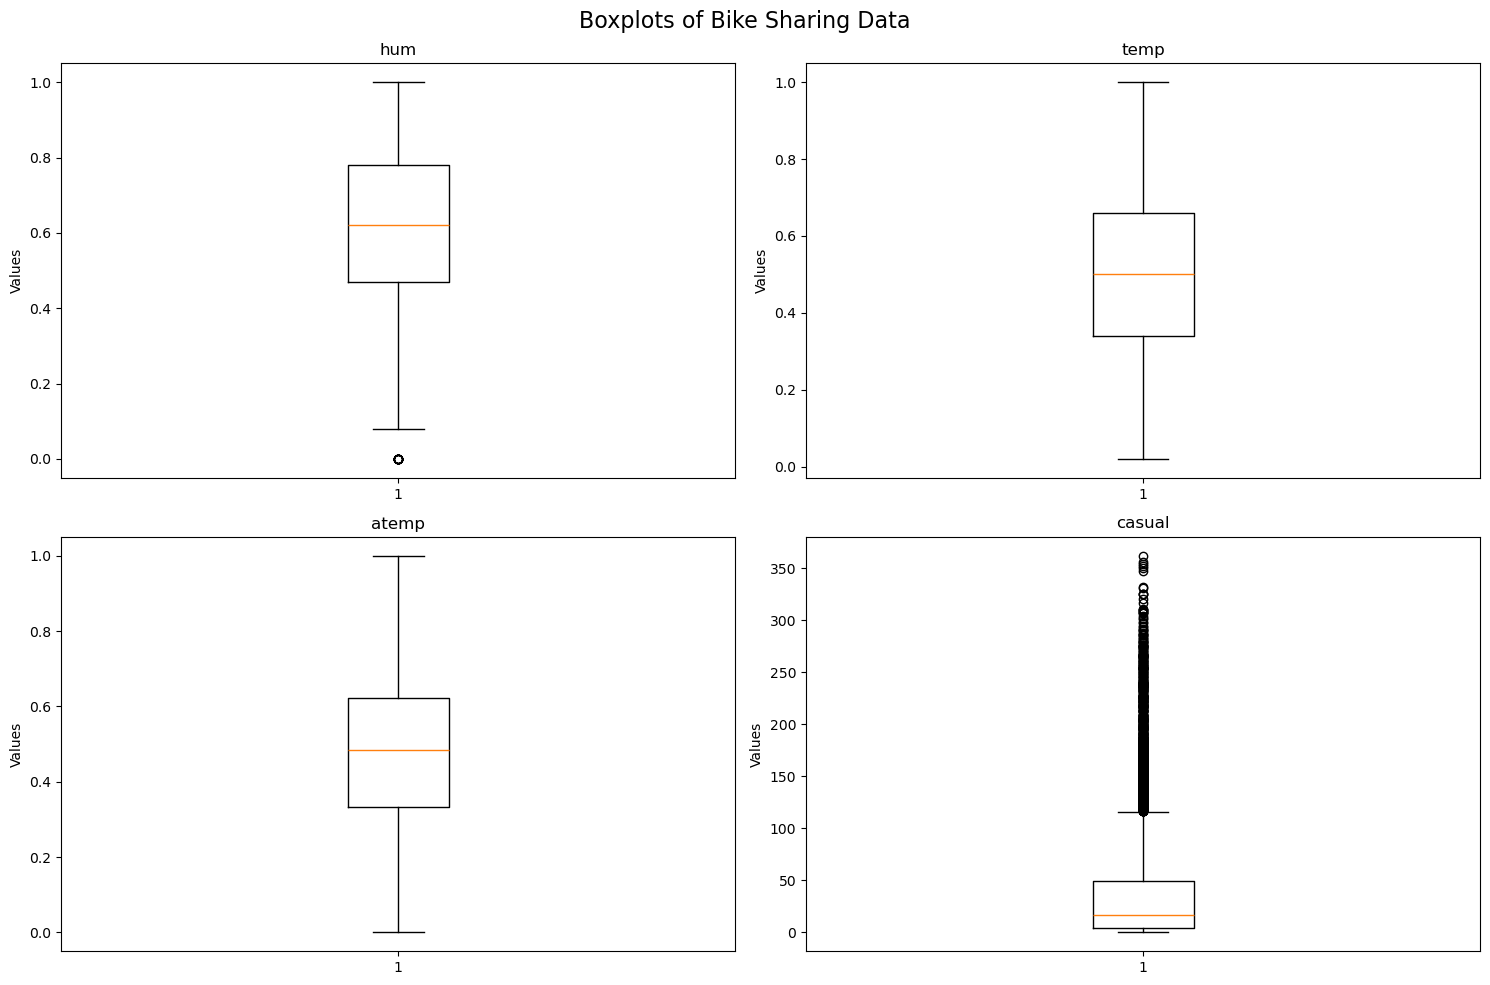

In [13]:
# Set up the plot
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Boxplots of Bike Sharing Data', fontsize=16)

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Create boxplots using a for loop
for i, column in enumerate(num_columns):
    axes[i].boxplot(bike[column])
    axes[i].set_title(column)
    axes[i].set_ylabel('Values')

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

In [14]:
# Outliers for casual check
outliers = bike[bike['casual'] >= 300]

# Count occurrences of each dteday
dteday_counts = outliers['dteday'].value_counts()

# Filter for dteday values that occur more than once
repeated_dtedays = dteday_counts[dteday_counts > 1].index

# Filter outliers for those dteday values
outliers_with_repeated_dtedays = outliers[outliers['dteday'].isin(repeated_dtedays)]
outliers_with_repeated_dtedays.sort_values(by='casual', ascending=False)


,dteday,hum,weathersit,holiday,season,atemp,temp,hr,casual,registered,cnt,day,month
6971,2012-10-06,0.54,1,0,4,0.6515,0.70,12,362,381,743,5,10
3283,2012-05-19,0.30,1,0,2,0.6515,0.72,15,356,316,672,5,5
2412,2012-04-07,0.19,1,0,2,0.5152,0.54,16,354,261,615,5,4
7395,2012-09-15,0.36,2,0,3,0.6212,0.66,16,350,433,783,5,9
9256,2012-10-20,0.37,1,0,4,0.5152,0.54,17,347,384,731,5,10
9589,2012-05-19,0.37,1,0,2,0.6364,0.70,13,332,372,704,5,5
7354,2012-05-19,0.30,1,0,2,0.6515,0.74,16,331,311,642,5,5
1242,2012-10-20,0.42,1,0,4,0.5152,0.54,16,325,366,691,5,10
9717,2012-10-27,0.46,1,0,4,0.6212,0.60,14,325,425,750,5,10
8016,2012-09-15,0.34,1,0,3,0.6364,0.68,14,325,390,715,5,9


In [15]:
# Outliers for humidity check
outliers = bike[bike_new['hum'] <= 0.0500]
outliers

,dteday,hum,weathersit,holiday,season,atemp,temp,hr,casual,registered,cnt,day,month
345,2011-03-10,0.0,3,0,1,0.3939,0.38,7,1,36,37,3,3
871,2011-03-10,0.0,3,0,1,0.4394,0.44,15,3,11,14,3,3
1645,2011-03-10,0.0,3,0,1,0.3182,0.34,0,3,0,3,3,3
3239,2011-03-10,0.0,2,0,1,0.4394,0.44,17,2,109,111,3,3
3717,2011-03-10,0.0,2,0,1,0.3333,0.34,22,4,30,34,3,3
4924,2011-03-10,0.0,3,0,1,0.3333,0.36,6,0,12,12,3,3
7285,2011-03-10,0.0,3,0,1,0.3182,0.34,1,0,2,2,3,3
7760,2011-03-10,0.0,3,0,1,0.4242,0.42,12,4,30,34,3,3
8412,2011-03-10,0.0,3,0,1,0.3939,0.38,8,1,43,44,3,3
8960,2011-03-10,0.0,3,0,1,0.3485,0.34,23,1,26,27,3,3


In [16]:
results = {}

for col in num_columns:
    q3 = bike_new[col].describe().loc['75%']
    q1 = bike_new[col].describe().loc['25%']

    iqr = q3 - q1

    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr

    # Count outliers
    upper_outliers = (bike_new[col] > upper).sum()
    lower_outliers = (bike_new[col] < lower).sum()
    total_outliers = upper_outliers + lower_outliers

    # Calculate percentages
    total_count = len(bike_new[col])
    upper_percent = (upper_outliers / total_count) * 100
    lower_percent = (lower_outliers / total_count) * 100
    total_percent = (total_outliers / total_count) * 100

    results[col] = {
        'Upper fence': upper,
        'Lower fence': lower,
        'Upper outliers': upper_outliers,
        'Upper outliers %': upper_percent,
        'Lower outliers': lower_outliers,
        'Lower outliers %': lower_percent,
        'Total outliers': total_outliers,
        'Total outliers %': total_percent
    }
    
show_outliers = pd.DataFrame(results).T.sort_values(by='Total outliers', ascending=False)
show_outliers




,Upper fence,Lower fence,Upper outliers,Upper outliers %,Lower outliers,Lower outliers %,Total outliers,Total outliers %
casual,116.50000,-63.50000,847.0,6.962598,0.0,0.000000,847.0,6.962598
hum,1.24500,0.00500,0.0,0.000000,14.0,0.115084,14.0,0.115084
temp,1.14000,-0.14000,0.0,0.000000,0.0,0.000000,0.0,0.000000
atemp,1.05305,-0.09855,0.0,0.000000,0.0,0.000000,0.0,0.000000


In [21]:
bike_new = bike_new[bike_new['hum'] >= 0.00500]
print(bike_new.shape)

bike_new = bike_new[bike_new['casual'] <= 93.00000]
print(bike_new.shape)

(11304, 10)
(10949, 10)


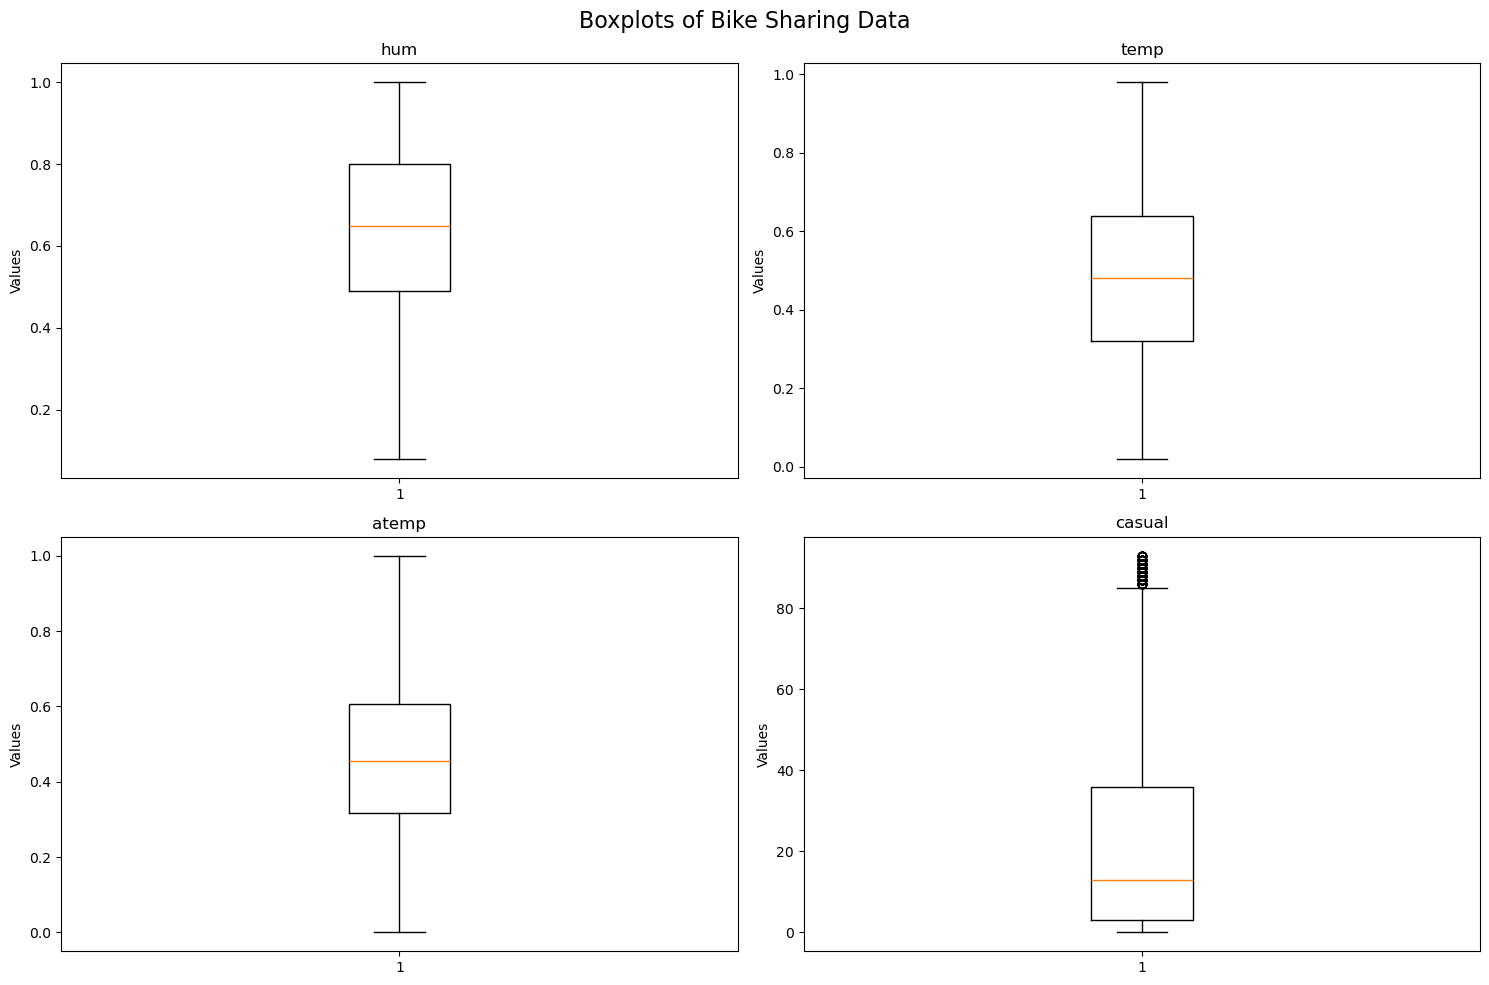

In [22]:
# Set up the plot
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Boxplots of Bike Sharing Data', fontsize=16)

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Create boxplots using a for loop
for i, column in enumerate(num_columns):
    axes[i].boxplot(bike_new[column])
    axes[i].set_title(column)
    axes[i].set_ylabel('Values')

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

In [23]:
results = {}

for col in num_columns:
    q3 = bike_new[col].describe().loc['75%']
    q1 = bike_new[col].describe().loc['25%']

    iqr = q3 - q1

    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr

    # Count outliers
    upper_outliers = (bike_new[col] > upper).sum()
    lower_outliers = (bike_new[col] < lower).sum()
    total_outliers = upper_outliers + lower_outliers

    # Calculate percentages
    total_count = len(bike_new[col])
    upper_percent = (upper_outliers / total_count) * 100
    lower_percent = (lower_outliers / total_count) * 100
    total_percent = (total_outliers / total_count) * 100

    results[col] = {
        'Upper fence': upper,
        'Lower fence': lower,
        'Upper outliers': upper_outliers,
        'Upper outliers %': upper_percent,
        'Lower outliers': lower_outliers,
        'Lower outliers %': lower_percent,
        'Total outliers': total_outliers,
        'Total outliers %': total_percent
    }
    
show_outliers = pd.DataFrame(results).T.sort_values(by='Total outliers', ascending=False)
show_outliers




,Upper fence,Lower fence,Upper outliers,Upper outliers %,Lower outliers,Lower outliers %,Total outliers,Total outliers %
casual,85.50000,-46.50000,185.0,1.689652,0.0,0.0,185.0,1.689652
hum,1.26500,0.02500,0.0,0.000000,0.0,0.0,0.0,0.000000
temp,1.12000,-0.16000,0.0,0.000000,0.0,0.0,0.0,0.000000
atemp,1.03795,-0.11365,0.0,0.000000,0.0,0.0,0.0,0.000000


In [24]:
import numpy as np
import pandas as pd

def remove_outliers(bike_new, columns):
    bike_new_clean = bike_new.copy()
    for col in columns:
        Q1 = bike_new_clean[col].quantile(0.25)
        Q3 = bike_new_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        bike_new_clean = bike_new_clean[(bike_new_clean[col] >= lower_bound) & (bike_new_clean[col] <= upper_bound)]
    return bike_new_clean

# Assuming 'bike_new' is your DataFrame and you want to remove outliers from numeric columns
numeric_columns = bike_new.select_dtypes(include=[np.number]).columns
bike_new_without_outliers = remove_outliers(bike_new, numeric_columns)

print(f"Original shape: {bike_new.shape}")
print(f"Shape after removing outliers: {bike_new_without_outliers.shape}")

Original shape: (10949, 10)
Shape after removing outliers: (10469, 10)


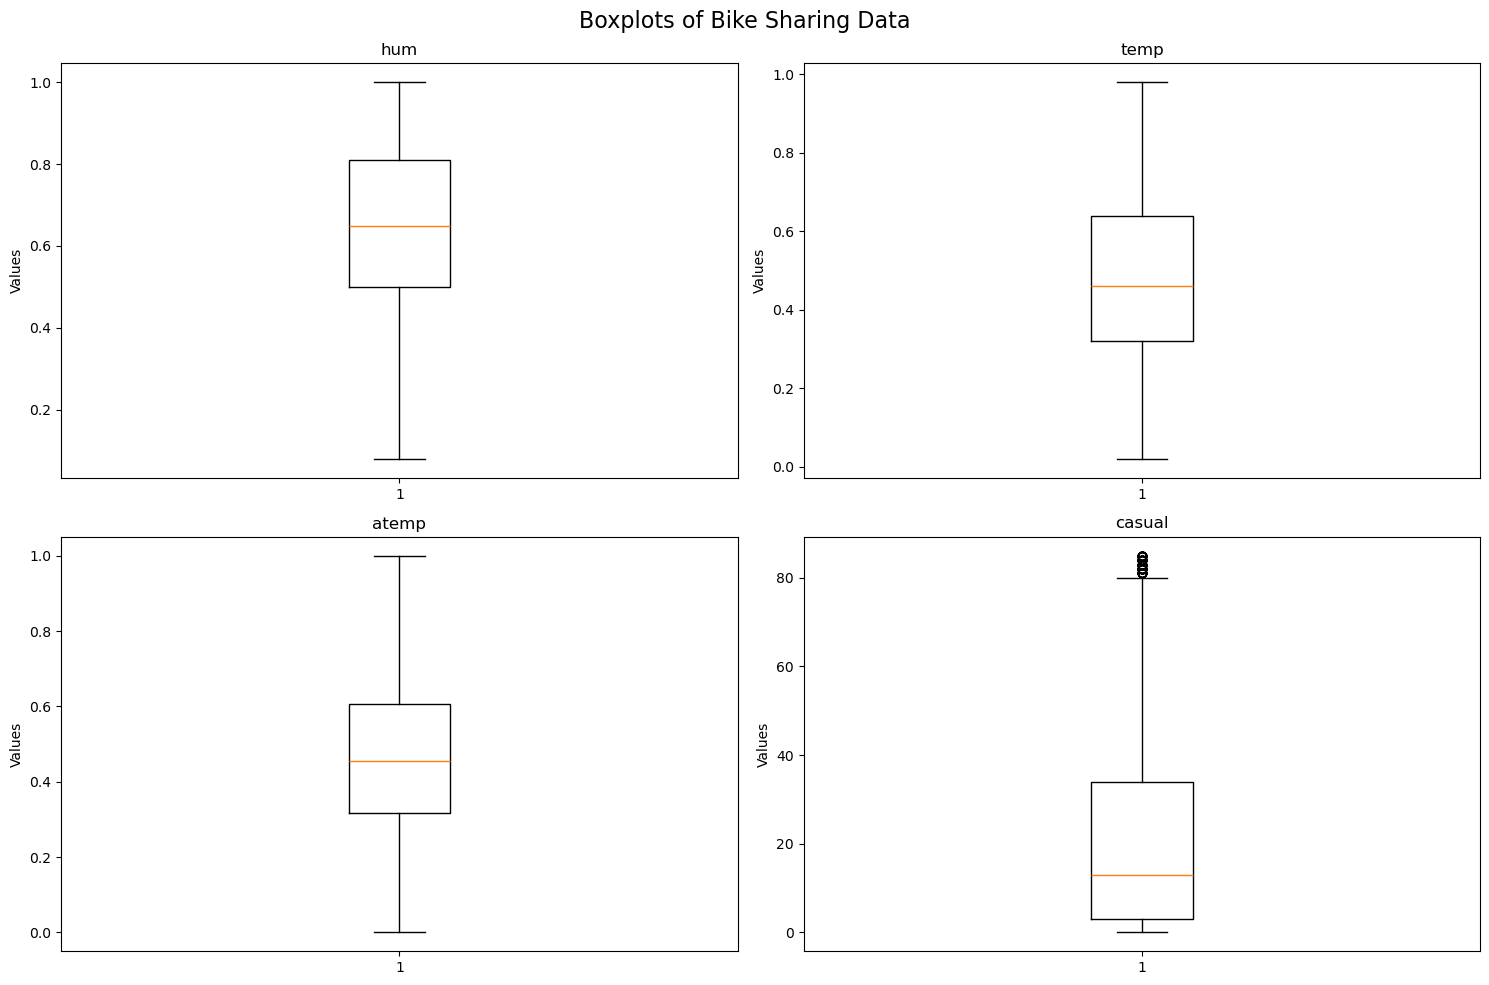

In [26]:
# Set up the plot
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Boxplots of Bike Sharing Data', fontsize=16)

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Create boxplots using a for loop
for i, column in enumerate(num_columns):
    axes[i].boxplot(bike_new_without_outliers[column])
    axes[i].set_title(column)
    axes[i].set_ylabel('Values')

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

In [18]:
bike_new.describe()

,hum,weathersit,holiday,season,temp,atemp,casual,day,month
count,11304.000000,11304.000000,11304.000000,11304.000000,11304.000000,11304.000000,11304.000000,11304.000000,11304.000000
mean,0.636489,1.429671,0.027424,2.471691,0.486177,0.466371,25.100938,2.859342,6.486553
std,0.189792,0.642096,0.163322,1.120097,0.191072,0.171096,27.608046,1.952872,3.497019
min,0.080000,1.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,0.490000,1.000000,0.000000,1.000000,0.320000,0.318200,3.000000,1.000000,3.000000
50%,0.640000,1.000000,0.000000,2.000000,0.480000,0.469700,14.000000,3.000000,7.000000
75%,0.790000,2.000000,0.000000,3.000000,0.640000,0.606100,39.000000,4.000000,10.000000
max,1.000000,4.000000,1.000000,4.000000,1.000000,1.000000,116.000000,6.000000,12.000000


Crime Rate
^
|        *    *
|    *       *    *  Predicted Line
| *     *    |----|    *  
|     *   *  /|----|/  
|____________________> Unemployment Rate


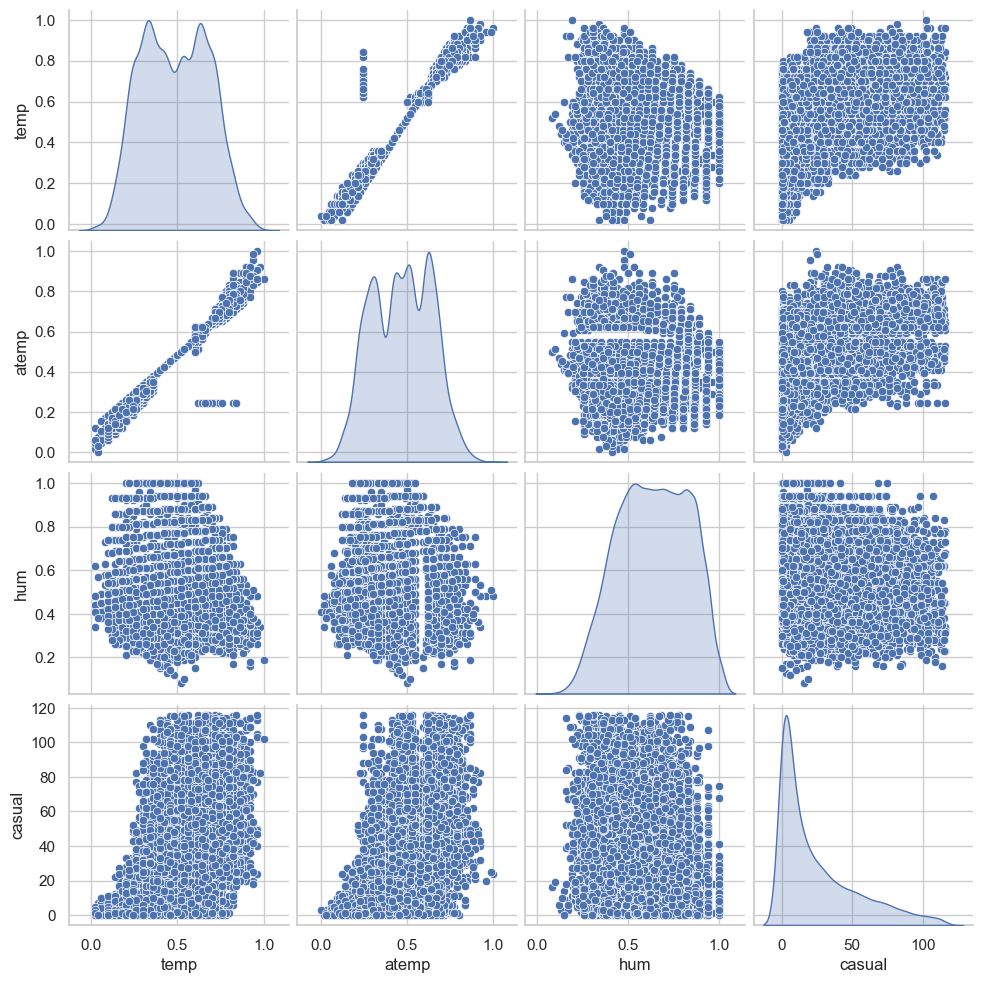

In [232]:
num_columns= bike_new[[ 'temp', 'atemp', 'hum', 'casual']]

sns.pairplot(num_columns, diag_kind='kde')
plt.show()

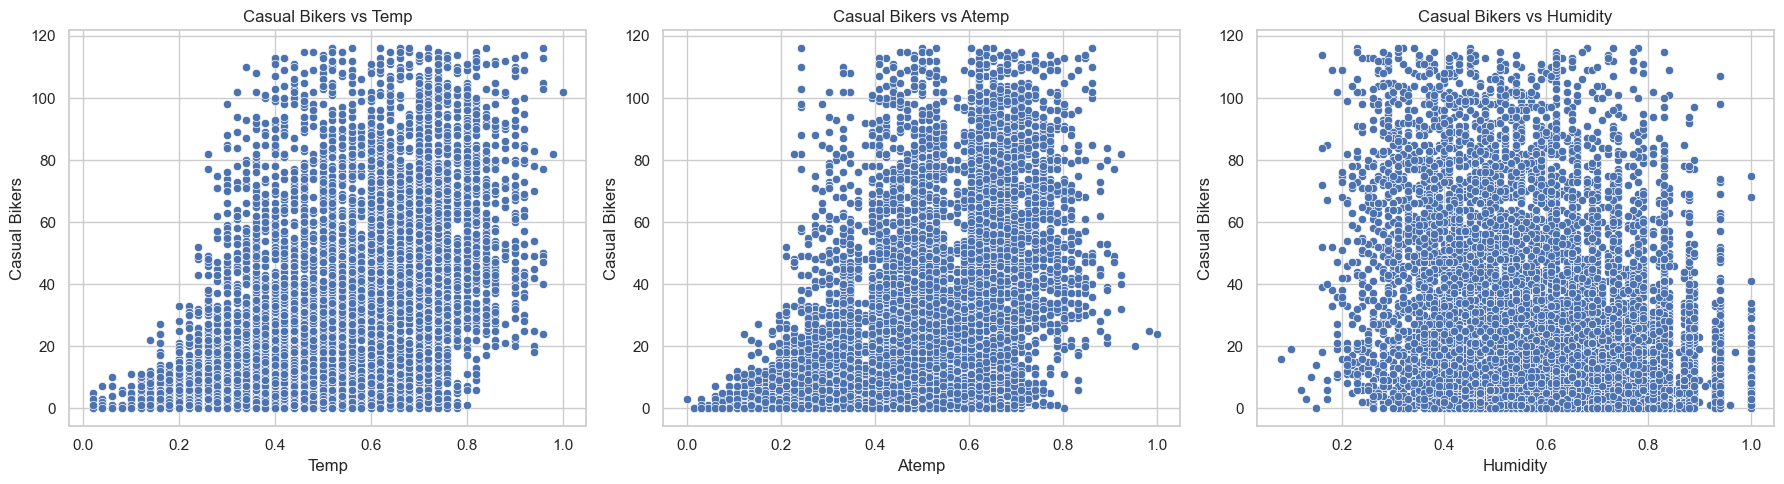

In [233]:

# Set up the plotting environment
sns.set(style="whitegrid")

# Create scatter plots for casual bikers against temp, atemp, and hum
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plot for temp vs casual
sns.scatterplot(ax=axes[0], x='temp', y='casual', data=bike_new)
axes[0].set_title('Casual Bikers vs Temp')
axes[0].set_xlabel('Temp')
axes[0].set_ylabel('Casual Bikers')

# Scatter plot for atemp vs casual
sns.scatterplot(ax=axes[1], x='atemp', y='casual', data=bike_new)
axes[1].set_title('Casual Bikers vs Atemp')
axes[1].set_xlabel('Atemp')
axes[1].set_ylabel('Casual Bikers')

# Scatter plot for hum vs casual
sns.scatterplot(ax=axes[2], x='hum', y='casual', data=bike_new)
axes[2].set_title('Casual Bikers vs Humidity')
axes[2].set_xlabel('Humidity')
axes[2].set_ylabel('Casual Bikers')

# Show the plots
plt.tight_layout()
plt.show()

In [234]:
sm_lm = sm.OLS(bike_new['casual'], sm.add_constant(bike_new[['temp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.277
Model:                            OLS   Adj. R-squared:                  0.276
Method:                 Least Squares   F-statistic:                     4320.
Date:                Tue, 02 Jul 2024   Prob (F-statistic):               0.00
Time:                        22:00:19   Log-Likelihood:                -51717.
No. Observations:               11304   AIC:                         1.034e+05
Df Residuals:                   11302   BIC:                         1.035e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -11.8406      0.604    -19.608      0.0

In [235]:
sm_lm = sm.OLS(bike_new['casual'], sm.add_constant(bike_new[['atemp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.267
Model:                            OLS   Adj. R-squared:                  0.267
Method:                 Least Squares   F-statistic:                     4127.
Date:                Tue, 02 Jul 2024   Prob (F-statistic):               0.00
Time:                        22:00:20   Log-Likelihood:                -51788.
No. Observations:               11304   AIC:                         1.036e+05
Df Residuals:                   11302   BIC:                         1.036e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -13.8180      0.645    -21.412      0.0

In [236]:
sm_lm = sm.OLS(bike_new['casual'], sm.add_constant(bike_new[['hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.128
Model:                            OLS   Adj. R-squared:                  0.128
Method:                 Least Squares   F-statistic:                     1664.
Date:                Tue, 02 Jul 2024   Prob (F-statistic):               0.00
Time:                        22:00:20   Log-Likelihood:                -52771.
No. Observations:               11304   AIC:                         1.055e+05
Df Residuals:                   11302   BIC:                         1.056e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         58.2695      0.848     68.675      0.0

In [237]:
sm_lm = sm.OLS(bike_new['casual'], sm.add_constant(bike_new[['temp','atemp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.277
Model:                            OLS   Adj. R-squared:                  0.277
Method:                 Least Squares   F-statistic:                     2162.
Date:                Tue, 02 Jul 2024   Prob (F-statistic):               0.00
Time:                        22:00:20   Log-Likelihood:                -51716.
No. Observations:               11304   AIC:                         1.034e+05
Df Residuals:                   11301   BIC:                         1.035e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -11.3559      0.673    -16.869      0.0

In [238]:
sm_lm = sm.OLS(bike_new['casual'], sm.add_constant(bike_new[['temp','hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.395
Model:                            OLS   Adj. R-squared:                  0.395
Method:                 Least Squares   F-statistic:                     3691.
Date:                Tue, 02 Jul 2024   Prob (F-statistic):               0.00
Time:                        22:00:21   Log-Likelihood:                -50706.
No. Observations:               11304   AIC:                         1.014e+05
Df Residuals:                   11301   BIC:                         1.014e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         20.6980      0.885     23.393      0.0

In [239]:
sm_lm = sm.OLS(bike_new['casual'], sm.add_constant(bike_new[['atemp','hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.392
Model:                            OLS   Adj. R-squared:                  0.392
Method:                 Least Squares   F-statistic:                     3644.
Date:                Tue, 02 Jul 2024   Prob (F-statistic):               0.00
Time:                        22:00:21   Log-Likelihood:                -50734.
No. Observations:               11304   AIC:                         1.015e+05
Df Residuals:                   11301   BIC:                         1.015e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         19.1352      0.903     21.201      0.0

In [240]:
sm_lm = sm.OLS(bike_new['casual'], sm.add_constant(bike_new[['temp','atemp','hum']]))
result = sm_lm.fit()

In [241]:
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.396
Model:                            OLS   Adj. R-squared:                  0.395
Method:                 Least Squares   F-statistic:                     2465.
Date:                Tue, 02 Jul 2024   Prob (F-statistic):               0.00
Time:                        22:00:21   Log-Likelihood:                -50701.
No. Observations:               11304   AIC:                         1.014e+05
Df Residuals:                   11300   BIC:                         1.014e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         20.0876      0.907     22.136      0.0

In [243]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
def calc_vif(X):

    # Calculating VIF
    vif = pd.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    return(vif)

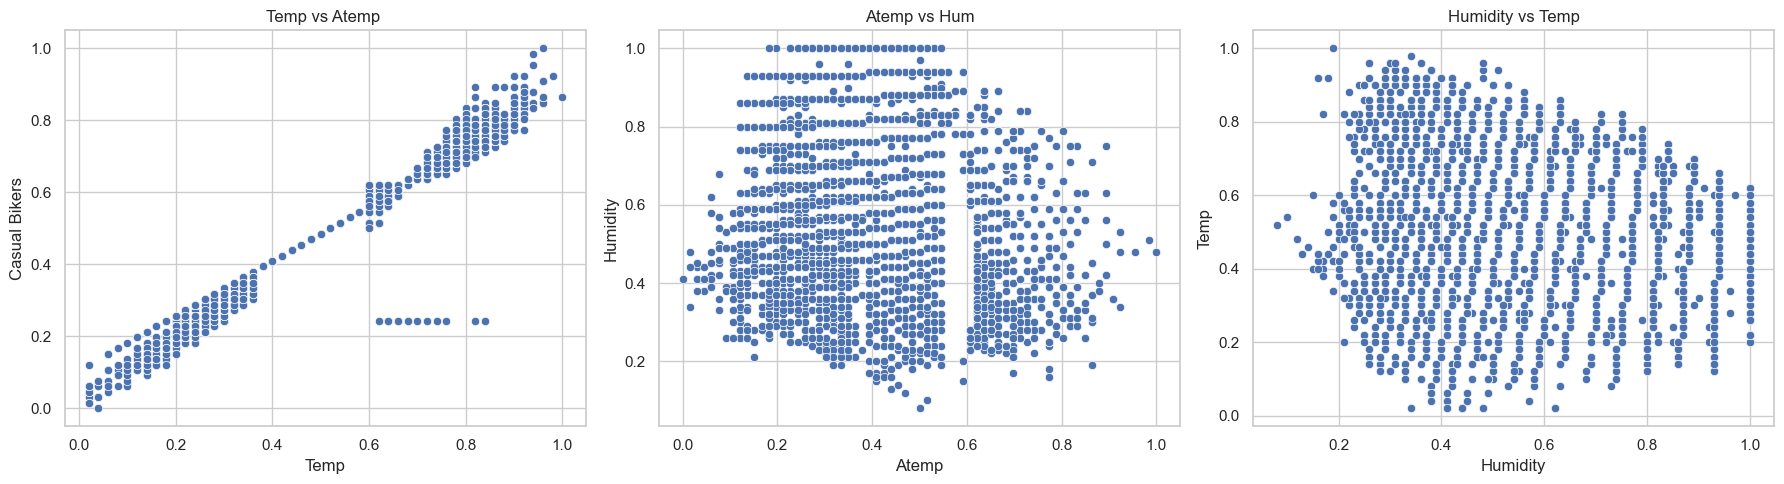

In [244]:
# Set up the plotting environment
sns.set(style="whitegrid")

# Create scatter plots for casual bikers against temp, atemp, and hum
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plot for temp vs casual
sns.scatterplot(ax=axes[0], x='temp', y='atemp', data=bike_new)
axes[0].set_title('Temp vs Atemp ')
axes[0].set_xlabel('Temp')
axes[0].set_ylabel('Casual Bikers')

# Scatter plot for atemp vs casual
sns.scatterplot(ax=axes[1], x='atemp', y='hum', data=bike_new)
axes[1].set_title('Atemp vs Hum')
axes[1].set_xlabel('Atemp')
axes[1].set_ylabel('Humidity')

# Scatter plot for hum vs casual
sns.scatterplot(ax=axes[2], x='hum', y='temp', data=bike_new)
axes[2].set_title('Humidity vs Temp')
axes[2].set_xlabel('Humidity')
axes[2].set_ylabel('Temp')

# Show the plots
plt.tight_layout()
plt.show()


In [245]:
calc_vif(bike_new[['temp','atemp']])

,variables,VIF
0,temp,270.27378
1,atemp,270.27378


In [246]:
calc_vif(bike_new[['temp','hum']])

,variables,VIF
0,temp,4.774027
1,hum,4.774027


In [247]:
calc_vif(bike_new[['atemp','hum']])

,variables,VIF
0,atemp,5.197633
1,hum,5.197633


In [248]:
calc_vif(bike_new[['temp','atemp','hum']])

,variables,VIF
0,temp,296.137637
1,atemp,322.414292
2,hum,5.695020



<center>

| F | p-value | R-squared | Adj. R-squared | X1 | X2 | X3 | VIF |
|---------|-------------------------|------------------------|--------------|--------------|--------------|--------------|--------------|
| 4320    | 0.00               | 0.277              | 0.276    | X    |     |     | 1.00    |
| 4127    | 0.00               | 0.267               | 0.267    |     | X    |     |1.00   |
| 0.267  | 0.00                | 0.128               | 0.128    |     |     | X     | 1.00    |
| 2162    | 0.00                | 0.277               | 0.277    | X    | X    |     | 270.27   |
| 3691    | 0.00                | 0.395               | 0.395   | X    |     | X    | 4.77    |
| 3644    | 0.00                | 0.392               | 0.392  |     | X    | X    | 5.19    |
| 2465    | 0.00                | 0.396               | 0.395 |  X   |  X   |  X   | below   |
|     |     |     |     | 296.13    | 322.4    | 5.69    |     |
<center>

# Model Improvement (Dummy Variables)

In [249]:
cat_columns = bike_new[['weathersit','season','hr','holiday','day','month']]


bike_new['season']=bike_new['season'].astype('category')
bike_new['weathersit']=bike_new['weathersit'].astype('category')
bike_new['month']=bike_new['month'].astype('category')
bike_new['day']=bike_new['day'].astype('category')
bike_new['hr']=bike_new['hr'].astype('category')
bike_new['holiday']=bike_new['holiday'].astype('category')

In [250]:
bike_new.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11304 entries, 0 to 12164
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   hum         11304 non-null  float64 
 1   weathersit  11304 non-null  category
 2   holiday     11304 non-null  category
 3   season      11304 non-null  category
 4   temp        11304 non-null  float64 
 5   atemp       11304 non-null  float64 
 6   hr          11304 non-null  category
 7   casual      11304 non-null  int64   
 8   day         11304 non-null  category
 9   month       11304 non-null  category
dtypes: category(6), float64(3), int64(1)
memory usage: 509.1 KB


In [251]:
bike_new = pd.get_dummies(bike_new, drop_first=True)
bool_columns = bike_new.select_dtypes(include=['bool']).columns
bike_new[bool_columns] = bike_new[bool_columns].astype('uint8')
bike_new.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11304 entries, 0 to 12164
Data columns (total 31 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   hum           11304 non-null  float64
 1   temp          11304 non-null  float64
 2   atemp         11304 non-null  float64
 3   casual        11304 non-null  int64  
 4   weathersit_2  11304 non-null  uint8  
 5   weathersit_3  11304 non-null  uint8  
 6   weathersit_4  11304 non-null  uint8  
 7   holiday_1     11304 non-null  uint8  
 8   season_2      11304 non-null  uint8  
 9   season_3      11304 non-null  uint8  
 10  season_4      11304 non-null  uint8  
 11  hr_Morning    11304 non-null  uint8  
 12  hr_Day        11304 non-null  uint8  
 13  hr_Evening    11304 non-null  uint8  
 14  day_1         11304 non-null  uint8  
 15  day_2         11304 non-null  uint8  
 16  day_3         11304 non-null  uint8  
 17  day_4         11304 non-null  uint8  
 18  day_5         11304 non-null  u

In [252]:
bike_new.head()

,hum,temp,atemp,casual,weathersit_2,weathersit_3,weathersit_4,holiday_1,season_2,season_3,...,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
0,0.62,0.36,0.3485,24,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,0.64,0.54,0.5152,2,0,0,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0
2,0.53,0.62,0.6212,17,0,0,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0
3,0.87,0.36,0.3485,19,1,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0
4,0.55,0.76,0.6970,99,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0


# Data Splitting

In [253]:
X = bike_new.drop(columns=['atemp','casual'])
y = bike_new['casual']

In [254]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

In [255]:
# Scaling
scaler = MinMaxScaler()


In [256]:
num_feat = ['temp','hum']
X_train[num_feat] = scaler.fit_transform(X_train[num_feat])

In [257]:
# Importing RFE and LinearRegression
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

In [258]:
lm = LinearRegression()
lm.fit(X_train, y_train)

rfe = RFE(estimator=lm, n_features_to_select=15)  
rfe = rfe.fit(X_train, y_train)

In [259]:
list(zip(X_train.columns,rfe.support_,rfe.ranking_))

[('hum', True, 1),
 ('temp', True, 1),
 ('weathersit_2', False, 14),
 ('weathersit_3', True, 1),
 ('weathersit_4', True, 1),
 ('holiday_1', True, 1),
 ('season_2', True, 1),
 ('season_3', False, 12),
 ('season_4', False, 11),
 ('hr_Morning', True, 1),
 ('hr_Day', True, 1),
 ('hr_Evening', True, 1),
 ('day_1', False, 7),
 ('day_2', False, 6),
 ('day_3', False, 8),
 ('day_4', True, 1),
 ('day_5', True, 1),
 ('day_6', True, 1),
 ('month_2', False, 9),
 ('month_3', False, 3),
 ('month_4', False, 13),
 ('month_5', False, 10),
 ('month_6', True, 1),
 ('month_7', True, 1),
 ('month_8', False, 15),
 ('month_9', False, 5),
 ('month_10', True, 1),
 ('month_11', False, 2),
 ('month_12', False, 4)]

In [260]:
col = X_train.columns[rfe.support_]
col

Index(['hum', 'temp', 'weathersit_3', 'weathersit_4', 'holiday_1', 'season_2',
       'hr_Morning', 'hr_Day', 'hr_Evening', 'day_4', 'day_5', 'day_6',
       'month_6', 'month_7', 'month_10'],
      dtype='object')

In [261]:
X_train.columns[~rfe.support_]

Index(['weathersit_2', 'season_3', 'season_4', 'day_1', 'day_2', 'day_3',
       'month_2', 'month_3', 'month_4', 'month_5', 'month_8', 'month_9',
       'month_11', 'month_12'],
      dtype='object')

In [262]:
# Creating X_test dataframe with RFE selected variables
X_train_rfe = X_train[col]

# Create a dataframe that will contain the names of all the feature variables and their respective VIFs
vif = pd.DataFrame()
vif['Features'] = X_train_rfe.columns

# Convert X_train_rfe values to numeric type, handling non-finite values
X_train_rfe_values = np.nan_to_num(X_train_rfe.values.astype(float)) 

vif['VIF'] = [variance_inflation_factor(X_train_rfe_values, i) for i in range(X_train_rfe.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
1,temp,9.03
0,hum,6.39
8,hr_Evening,1.81
7,hr_Day,1.80
6,hr_Morning,1.77
5,season_2,1.57
13,month_7,1.52
12,month_6,1.35
2,weathersit_3,1.22
9,day_4,1.21


In [263]:
X_train_rfe

,hum,temp,weathersit_3,weathersit_4,holiday_1,season_2,hr_Morning,hr_Day,hr_Evening,day_4,day_5,day_6,month_6,month_7,month_10
10530,0.456522,0.612245,0,0,0,0,1,0,0,0,0,0,0,0,0
9197,0.576087,0.306122,0,0,0,1,0,0,0,0,0,0,0,0,0
10442,0.706522,0.591837,0,0,0,1,0,1,0,0,0,0,0,0,0
11908,0.815217,0.612245,1,0,0,0,1,0,0,0,0,1,0,0,0
4363,0.663043,0.204082,0,0,0,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12145,0.880435,0.673469,0,0,0,0,1,0,0,0,0,0,0,0,0
5603,0.576087,0.612245,0,0,0,0,0,0,1,0,0,0,0,0,0
5812,0.869565,0.591837,1,0,0,1,0,0,1,1,0,0,1,0,0
935,0.934783,0.612245,0,0,0,0,1,0,0,0,0,1,0,1,0


In [264]:
# Add a constant
X_train_lm1 = sm.add_constant(X_train_rfe)

# Create a first fitted model
lr1 = sm.OLS(y_train, X_train_lm1).fit()

In [265]:
print(lr1.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.568
Model:                            OLS   Adj. R-squared:                  0.568
Method:                 Least Squares   F-statistic:                     792.7
Date:                Tue, 02 Jul 2024   Prob (F-statistic):               0.00
Time:                        22:02:29   Log-Likelihood:                -39080.
No. Observations:                9043   AIC:                         7.819e+04
Df Residuals:                    9027   BIC:                         7.831e+04
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          -12.8057      0.950    -13.483   

In [266]:
X_train_new = X_train_rfe.drop(["weathersit_4"], axis = 1)

In [267]:
vif = pd.DataFrame()
vif['Features'] = X_train_new.columns
vif['VIF'] = [variance_inflation_factor(X_train_new.values, i) for i in range(X_train_new.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
1,temp,9.03
0,hum,6.39
7,hr_Evening,1.81
6,hr_Day,1.80
5,hr_Morning,1.77
4,season_2,1.57
12,month_7,1.52
11,month_6,1.35
2,weathersit_3,1.22
8,day_4,1.21


In [268]:
# Add a constant
X_train_lm2 = sm.add_constant(X_train_new)

# Create a first fitted model
lr2 = sm.OLS(y_train, X_train_lm2).fit()

In [269]:
# Print a summary of the linear regression model obtained
print(lr2.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.568
Model:                            OLS   Adj. R-squared:                  0.568
Method:                 Least Squares   F-statistic:                     849.2
Date:                Tue, 02 Jul 2024   Prob (F-statistic):               0.00
Time:                        22:04:25   Log-Likelihood:                -39080.
No. Observations:                9043   AIC:                         7.819e+04
Df Residuals:                    9028   BIC:                         7.830e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          -12.8013      0.950    -13.478   

In [274]:
X_train_new = X_train_rfe.drop(['hum','weathersit_4'], axis = 1)

In [275]:
vif = pd.DataFrame()
vif['Features'] = X_train_new.columns
vif['VIF'] = [variance_inflation_factor(X_train_new.values, i) for i in range(X_train_new.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
0,temp,5.02
6,hr_Evening,1.81
5,hr_Day,1.77
4,hr_Morning,1.69
3,season_2,1.56
11,month_7,1.44
10,month_6,1.29
7,day_4,1.20
9,day_6,1.15
8,day_5,1.14


In [276]:
X_train_lm3 = sm.add_constant(X_train_new)

# Create a first fitted model
lr3 = sm.OLS(y_train, X_train_lm3).fit()

In [277]:
print(lr3.summary())

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.537
Model:                            OLS   Adj. R-squared:                  0.537
Method:                 Least Squares   F-statistic:                     807.2
Date:                Tue, 02 Jul 2024   Prob (F-statistic):               0.00
Time:                        22:09:31   Log-Likelihood:                -39393.
No. Observations:                9043   AIC:                         7.881e+04
Df Residuals:                    9029   BIC:                         7.891e+04
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          -30.3665      0.675    -45.018   

In [278]:
y_train_pred = lr3.predict(X_train_lm3)

Text(0.5, 0, 'Errors')

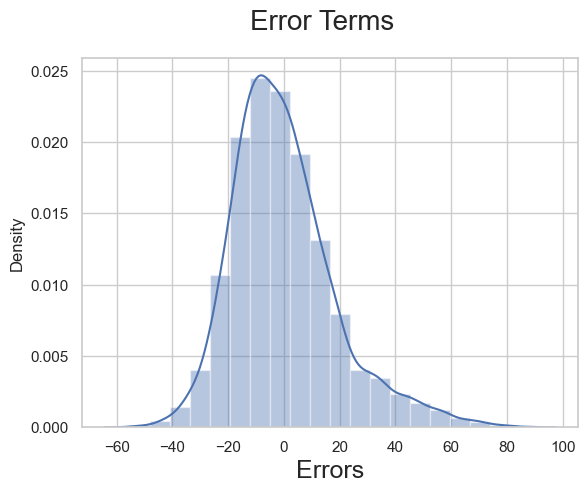

In [283]:
res = y_train-y_train_pred
# Plot the histogram of the error terms
fig = plt.figure()
sns.distplot((res), bins = 20)
fig.suptitle('Error Terms', fontsize = 20)                  # Plot heading 
plt.xlabel('Errors', fontsize = 18)   

In [286]:
col1=X_train_new.columns
X_test=X_test[col1]
# Adding constant variable to test dataframe
X_test_lm3 = sm.add_constant(X_test)
X_test_lm3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2261 entries, 9420 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   const         2261 non-null   float64
 1   temp          2261 non-null   float64
 2   weathersit_3  2261 non-null   uint8  
 3   holiday_1     2261 non-null   uint8  
 4   season_2      2261 non-null   uint8  
 5   hr_Morning    2261 non-null   uint8  
 6   hr_Day        2261 non-null   uint8  
 7   hr_Evening    2261 non-null   uint8  
 8   day_4         2261 non-null   uint8  
 9   day_5         2261 non-null   uint8  
 10  day_6         2261 non-null   uint8  
 11  month_6       2261 non-null   uint8  
 12  month_7       2261 non-null   uint8  
 13  month_10      2261 non-null   uint8  
dtypes: float64(2), uint8(12)
memory usage: 79.5 KB


In [287]:
y_pred = lr3.predict(X_test_lm3)

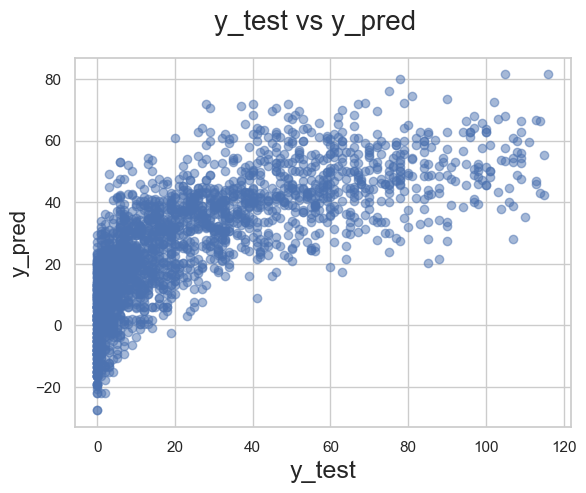

In [288]:
# Plotting y_test and y_pred to understand the spread

fig = plt.figure()
plt.scatter(y_test, y_pred, alpha=.5)
fig.suptitle('y_test vs y_pred', fontsize = 20)              # Plot heading 
plt.xlabel('y_test', fontsize = 18)                          # X-label
plt.ylabel('y_pred', fontsize = 16) 
plt.show()

In [289]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.5358741266750742

In [290]:
# We already have the value of R^2 (calculated in above step)

r2=0.5358741266750742

In [291]:
n = X_test.shape[0]


# Number of features (predictors, p) is the shape along axis 1
p = X_test.shape[1]

# We find the Adjusted R-squared using the formula

adjusted_r2 = 1-(1-r2)*(n-1)/(n-p-1)
adjusted_r2

0.5331889302561938

In [304]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)



# Print RMSE
print(f"RMSE: {rmse}")
print(f"MAE: {mae}")




RMSE: 18.44865890330667
MAE: 14.200219641856911


In [20]:
bike['hr']

(12165,)